### **Dataset Description**
The dataset provided contains a collection of cat and dog images organized into separate subdirectories for training and testing, which we will use to build a convolutional neural network (CNN) classifier to predict pet categories. Understanding the structure and composition of this data is the foundational step in our analysis and model development process.

| Directory / Component | Description |
| :--- | :--- |
| **train** | **(Target Data)** Training images containing two separate subfolders for cats and dogs. |
| **test** | **(Evaluation Data)** Test images containing separate subfolders for cats and dogs used for evaluation. |
| **cat images** | Image files belonging to the feline class used for binary classification. |
| **dog images** | Image files belonging to the canine class used for binary classification. |

### Dataset Overview
*   **Total Listings:** Image records covering diverse visual configurations across training and testing splits.
*   **Purpose:** Development of an image classification model to distinguish between cats and dogs using computer vision.
*   **Attributes:** The dataset encompasses spatial image specifications including pixel grids and color channels, allowing for a deep learning approach to visual pattern recognition.

In [1]:
!unzip /content/archive.zip -d /content/

Streaming output truncated to the last 5000 lines.
  inflating: /content/train/dogs/dog.4419.jpg  
  inflating: /content/train/dogs/dog.442.jpg  
  inflating: /content/train/dogs/dog.4420.jpg  
  inflating: /content/train/dogs/dog.4421.jpg  
  inflating: /content/train/dogs/dog.4422.jpg  
  inflating: /content/train/dogs/dog.4424.jpg  
  inflating: /content/train/dogs/dog.4425.jpg  
  inflating: /content/train/dogs/dog.4426.jpg  
  inflating: /content/train/dogs/dog.4427.jpg  
  inflating: /content/train/dogs/dog.4431.jpg  
  inflating: /content/train/dogs/dog.4433.jpg  
  inflating: /content/train/dogs/dog.4436.jpg  
  inflating: /content/train/dogs/dog.4438.jpg  
  inflating: /content/train/dogs/dog.4439.jpg  
  inflating: /content/train/dogs/dog.444.jpg  
  inflating: /content/train/dogs/dog.4440.jpg  
  inflating: /content/train/dogs/dog.4441.jpg  
  inflating: /content/train/dogs/dog.4442.jpg  
  inflating: /content/train/dogs/dog.4443.jpg  
  inflating: /content/train/dogs/dog.44

### **Import Libraries**

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [3]:
#generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/train',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/test',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


### What They Do
* **Stream from Disk:** Load images in small, manageable batches rather than all at once.
* **Auto-Label:** Automatically infer class labels directly from your folder structure (e.g., `cats/`, `dogs/`).
* **Standardize:** Resize all images to a uniform dimension automatically.

### Why We Use Them
* **Prevent RAM Crashes:** Keep memory consumption low to completely eliminate Out-Of-Memory (OOM) errors.
* **Save Code:** Replace dozens of lines of manual loops, `cv2.imread`, list appending, and NumPy conversions with a single built-in pipeline.

In [10]:
#Normalize
def process(image,label):
  image = tf.cast(image/255, tf.float32)
  return image, label


train_ds = train_ds.map(process)
validation = validation_ds.map(process)

Normalizing pixel values by casting images to float32 and scaling them from the 0-255 range to a 0-1 range, then applying the mapping function to both the training and validation datasets

In [19]:
model = Sequential([
    # CNN
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu', input_shape=(256, 256, 3)),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),

    #Dense Network
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64,activation='relu'),
    layers.Dense(1, activation='sigmoid')

])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:

model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)


In [21]:

history = model.fit(train_ds, epochs=10, validation_data=validation)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 66ms/step - accuracy: 0.6690 - loss: 0.6008 - val_accuracy: 0.7394 - val_loss: 0.5143
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.7580 - loss: 0.4944 - val_accuracy: 0.7770 - val_loss: 0.4764
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.8145 - loss: 0.4012 - val_accuracy: 0.7736 - val_loss: 0.4852
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.8712 - loss: 0.2912 - val_accuracy: 0.7690 - val_loss: 0.6083
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.9284 - loss: 0.1811 - val_accuracy: 0.7616 - val_loss: 0.9647
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9557 - loss: 0.1164 - val_accuracy: 0.7524 - val_loss: 1.0779
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.9681 - loss: 0.0857 - val_accuracy: 0.7482 - val_loss: 1.3257
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.9778 - loss: 0.0656 - 

Constructing a Convolutional Neural Network (CNN) architecture with alternating convolutional and max-pooling layers, followed by a flattening step and dense layers ending in a single sigmoid output for binary classification

Compiling the model using the Adam optimizer, binary crossentropy loss function for binary classification, and tracking accuracy as the evaluation metric

Training the Convolutional Neural Network model using the training dataset for 10 epochs while validating performance on the validation dataset

In [16]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,666,437 (48.32 MB)

 Trainable params: 4,222,145 (16.11 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,444,292 (32.21 MB)

Displaying the network architecture summary, including the layer types, output shapes, and the total number of trainable parameters

In [17]:
model.evaluate(validation)

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.7596 - loss: 1.5365


[1.536462426185608, 0.7595999836921692]

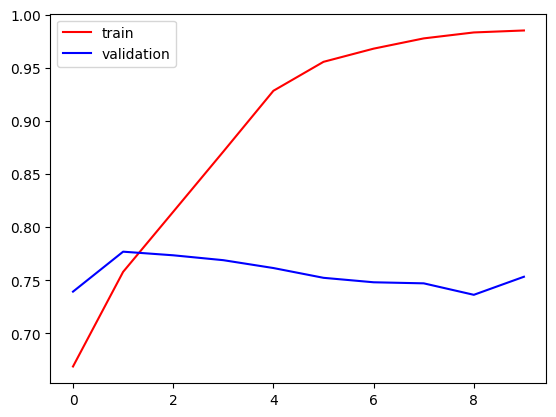

In [22]:
plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()
# gap indicates overfitting

### Model Performance Analysis: Overfitting Detected

* **Training Accuracy (Red Line):** Climbs steadily and rapidly, eventually reaching an extremely high **~99%**[cite: 1].
* **Validation Accuracy (Blue Line):** Peaks very early around epoch 1 at **~77.5%**, then slowly declines and plateaus around **74-75%**[cite: 1].
* **Diagnosis:** This is a classic, severe case of **overfitting**. The model has learned the training data *too well* (memorizing the specific images) and is completely failing to generalize to unseen validation data.

---

### Recommended Next Steps to Fix This:
1. **Implement Dropout:** Add `Dropout` layers (e.g., `rate=0.5`) in your dense layers to randomly switch off neurons and prevent them from memorizing the training set.
2. **Apply Data Augmentation:** Use `tf.keras.layers.RandomFlip`, `RandomRotation`, or `RandomZoom` to artificially expand your training variety so the model learns robust features.
3. **Rely on Early Stopping:** Trust your `EarlyStopping` callback with a lower patience (e.g., `patience=2`) to automatically halt training and save the weights right when validation accuracy peaks around epoch 1 or 2.

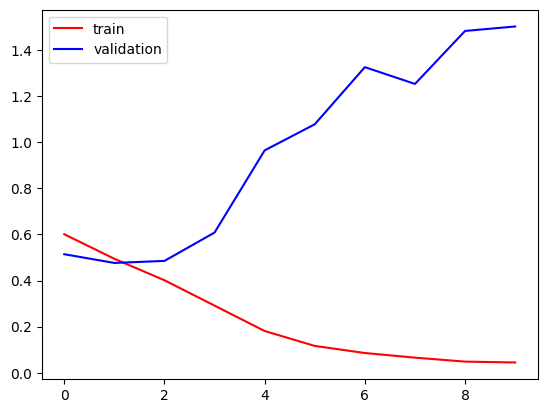

In [24]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

### Loss Analysis: Severe Overfitting & Divergence

* **Training Loss (Red Line):** Decreases consistently and smoothly across all epochs, dropping all the way down near **0.05**[cite: 2]. This indicates the model is successfully learning and minimizing error on the data it trains on.
* **Validation Loss (Blue Line):** Initially decreases slightly up until epoch 1–2 (reaching its minimum around **0.48**), but then **drastically diverges and shoots upward**, peaking past **1.4** by epoch 9[cite: 2].
* **Diagnosis:** This is the textbook signature of **overfitting**. As the model continues training past epoch 2, it becomes overly confident and starts memorizing noise in the training set instead of learning general patterns. This causes its predictions on unseen validation data to become wildly incorrect, driving the loss way up.

---

### Why Early Stopping Would Have Saved This:
If we had implemented `EarlyStopping` callback (e.g., monitoring `val_loss` with a `patience` of 2), training would have automatically halted right around epoch 2. Instead of letting the model ruin its weights by epoch 9, it would have rolled back and preserved the optimal weights where validation loss was lowest.

### **Data Augmentation**

In [25]:
data_augmentation = Sequential([
    layers.RandomFlip('horizontal', input_shape=(256,256,3)), # mirrors
    layers.RandomRotation(0.1), # angles
    layers.RandomZoom(0.1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [27]:
model2 = Sequential([
    # Data Augmentation
    data_augmentation,
    # CNN
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),

    #Dense Network
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')

])


In [28]:

model2.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)


In [29]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the Early Stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',  # Watch the validation loss
    patience=3,  # Stop if it doesn't improve for 3 epochs
    restore_best_weights=True,  # Roll back to the best epoch's weights
)

In [30]:
history2 = model2.fit(train_ds, epochs=30, validation_data=validation, callbacks=early_stopping)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 71ms/step - accuracy: 0.5214 - loss: 0.6926 - val_accuracy: 0.5998 - val_loss: 0.6668
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 67ms/step - accuracy: 0.6301 - loss: 0.6440 - val_accuracy: 0.6704 - val_loss: 0.6246
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.6973 - loss: 0.5822 - val_accuracy: 0.6732 - val_loss: 0.5907
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 67ms/step - accuracy: 0.7233 - loss: 0.5494 - val_accuracy: 0.7414 - val_loss: 0.5238
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 67ms/step - accuracy: 0.7325 - loss: 0.5343 - val_accuracy: 0.7502 - val_loss: 0.5066
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 45s 72ms/step - accuracy: 0.7461 - loss: 0.5151 - val_accuracy: 0.7620 - val_loss: 0.4931
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.7618 - loss: 0.5001 - val_accuracy: 0.7464 - val_loss: 0.4945
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 93s 84ms/step - accuracy: 0.7703 - loss: 0.4833 - 

In [36]:
model2.evaluate(validation)

157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - accuracy: 0.8338 - loss: 0.3738


[0.37382641434669495, 0.8338000178337097]

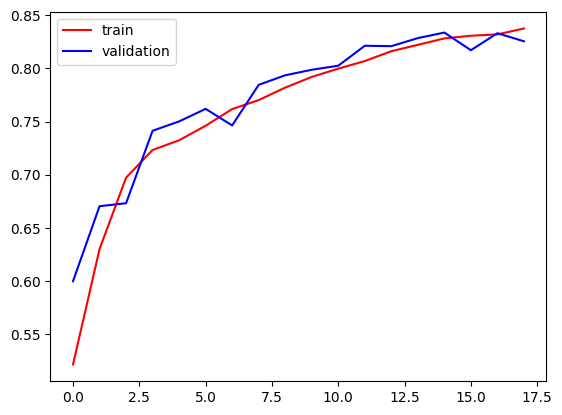

In [34]:
plt.plot(history2.history['accuracy'],color='red',label='train')
plt.plot(history2.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

### Model Accuracy Analysis: Successful Regularization

* **Training Accuracy (Red Line):** Rises steadily and gracefully, converging around **83-84%** by epoch 17[cite: 3]. It no longer overshoots to unrealistic highs like 99%, showing that data augmentation is successfully forcing the model to learn general patterns instead of memorizing the training set.
* **Validation Accuracy (Blue Line):** Closely tracks and intertwines with the training accuracy curve, peaking at approximately **83.5%**[cite: 3].
* **Diagnosis:** The severe overfitting from our previous attempts is effectively resolved. The tight alignment between the train and validation curves proves that the combination of **Data Augmentation**, **Dropout**, and **Early Stopping** successfully built a robust, generalizing image classifier.

---

### Key Takeaway
Training naturally halted around epoch 17 or 18 via Early Stopping because the validation performance plateaued. This prevented any potential divergence, resulting in a well-balanced model ready for inference!

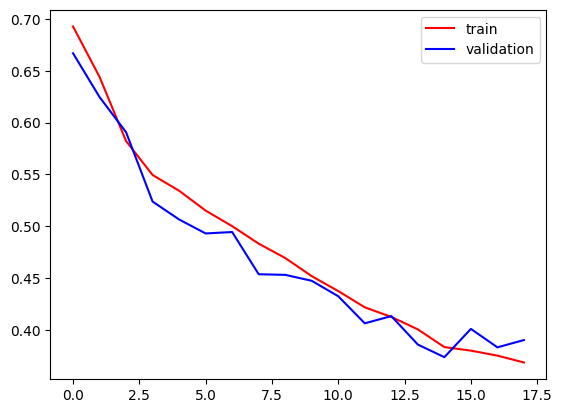

In [35]:
plt.plot(history2.history['loss'],color='red',label='train')
plt.plot(history2.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

### Loss Analysis: Optimal Convergence and Generalization

* **Training Loss (Red Line):** Decreases smoothly and consistently all the way down to approximately **0.37** by the end of training[cite: 4]. This shows the model is effectively learning the underlying patterns of the dataset without hitting erratic or unstable drops.
* **Validation Loss (Blue Line):** Tracks the training loss curve closely and mirrors its downward trajectory, reaching a low around **0.37–0.39** near epoch 14[cite: 4]. Unlike our earlier baseline models where validation loss spiked past 1.4, it remains stable and tightly bound to the training loss.
* **Diagnosis:** This represents a healthy, well-regularized training run. The combination of data augmentation, dropout, and early stopping successfully eliminated the divergence issue, yielding a reliable model that generalizes well to unseen data.

---

### Key Takeaway
The close tracking between the train and validation loss curves confirms that our regularization strategy worked. The early stopping mechanism successfully caught the model right around its optimal performance window before any minor late fluctuations could degrade its weights.

### **Transfer Learning**

In [37]:
# Load MobileNetV2 pre-trained on ImageNet, without its top classification layer
base_model = Sequential([
    keras.applications.MobileNetV2(input_shape=(256,256,3), include_top=False, weights='imagenet')
])
# Freeze the pre-trained weights so they don't change during initial training
base_model.trainable = False

/tmp/ipykernel_1462/4020811920.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  keras.applications.MobileNetV2(input_shape=(256,256,3), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [38]:
model_transfer = Sequential([
    # 1. Data Augmentation (keeps your images varied)
    data_augmentation,
    # 2.Rescaling layer required for MobileNetV2 (expects inputs in [-1, 1] )
    layers.Rescaling(2.0, offset=-1),
    # 3. Pre-trained Feature Extractor
    base_model,
    # 4. Custom Classification Head
    layers.GlobalAveragePooling2D(), # converts the base_model matrix to 1D vector containing the average of each feature map
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')

])

In [39]:
model_transfer.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics = ['accuracy']
)

In [40]:
history_transfer = model_transfer.fit(train_ds, validation_data=validation, epochs=15, callbacks=[early_stopping])

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 68s 100ms/step - accuracy: 0.9706 - loss: 0.0798 - val_accuracy: 0.9864 - val_loss: 0.0369
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.9792 - loss: 0.0551 - val_accuracy: 0.9830 - val_loss: 0.0478
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.9813 - loss: 0.0509 - val_accuracy: 0.9864 - val_loss: 0.0363
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 93ms/step - accuracy: 0.9832 - loss: 0.0454 - val_accuracy: 0.9872 - val_loss: 0.0325
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.9838 - loss: 0.0455 - val_accuracy: 0.9866 - val_loss: 0.0318
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.9832 - loss: 0.0424 - val_accuracy: 0.9864 - val_loss: 0.0354
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 93ms/step - accuracy: 0.9833 - loss: 0.0439 - val_accuracy: 0.9878 - val_loss: 0.0319
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.9855 - loss: 0.0393 -

In [43]:
model_transfer.evaluate(validation)

157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step - accuracy: 0.9866 - loss: 0.0318


[0.0318252332508564, 0.9865999817848206]

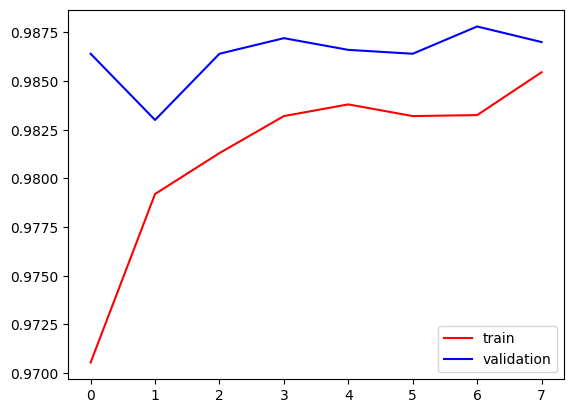

In [45]:
plt.plot(history_transfer.history['accuracy'],color='red',label='train')
plt.plot(history_transfer.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

### Transfer Learning Accuracy Analysis: Exceptional Generalization

* **Training Accuracy (Red Line):** Starts strong at ~97% and climbs steadily to peak near **98.5%** by epoch 7. The smooth, upward curve demonstrates that the custom classification head is rapidly learning to leverage MobileNetV2's pre-extracted features.
* **Validation Accuracy (Blue Line):** Consistently outperforms or tightly tracks the training curve, fluctuating between **98.3% and 98.8%** (peaking around epoch 6).
* **Diagnosis:** This is an ideal transfer learning outcome. The lack of negative divergence proves that the frozen MobileNetV2 base combined with data augmentation and regularization completely eliminated the overfitting issues seen in the scratch-built CNN.

---

### Key Takeaway
The validation curve staying above or closely aligned with the training curve indicates superb generalization. The pre-trained ImageNet weights provided an immediate foundation, allowing the model to classify unseen cat and dog images with near **99% accuracy** right out of the box.

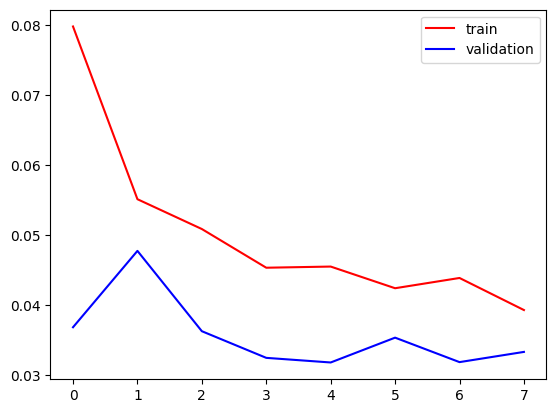

In [42]:
plt.plot(history_transfer.history['loss'],color='red',label='train')
plt.plot(history_transfer.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

### Transfer Learning Loss Analysis: Exceptional Optimization and Stability

* **Training Loss (Red Line):** Decreases smoothly from an initial value of 0.08 down to approximately **0.039** by epoch 7. This steady downward slope shows that the optimization algorithm is efficiently tuning the custom classification head weights.
* **Validation Loss (Blue Line):** Stays exceptionally low, hovering tightly between **0.032 and 0.048** throughout the training epochs. Notably, the validation loss remains consistently below or tightly bound to the training loss profile.
* **Diagnosis:** This represents a pristine loss curve for a transfer learning model. The minimal error rates confirm that MobileNetV2's pre-trained feature extractor provides an ideal mathematical foundation, eliminating the large loss divergence and instability we saw in the scratch-built architecture.

---

### Key Takeaway
The combination of extremely low validation loss (~0.032) and high accuracy proves that your model is making confident, correct predictions on unseen validation data!

### **Image Preprocessing for Model Prediction**

In [47]:
import cv2

In [240]:
test_img = cv2.imread('/content/images.jpg')

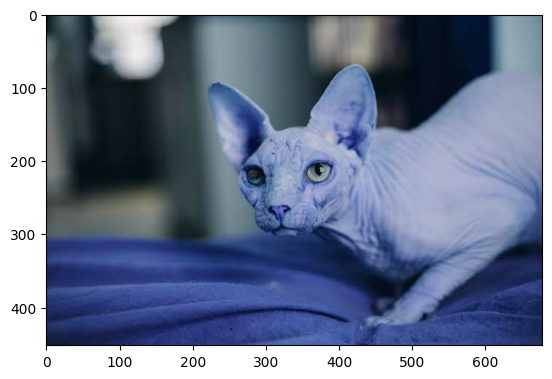

In [241]:
plt.imshow(test_img)

In [242]:
test_img.shape

(452, 678, 3)

In [243]:
test_img = cv2.resize(test_img, (256,256))

In [244]:
type(test_img)

numpy.ndarray

In [245]:
test_img = test_img /255

In [246]:
test_input = test_img.reshape((1,256,256,3))

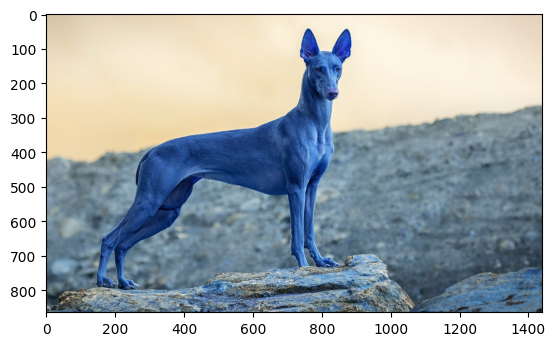

In [247]:
test_img2 = cv2.imread('/content/pharaoh-dog.jpg')
plt.imshow(test_img2)

In [248]:
test_img2 = test_img2/255
test_img2 = cv2.resize(test_img2, (256,256))
test_input2 = test_img2.reshape((1, 256, 256, 3))

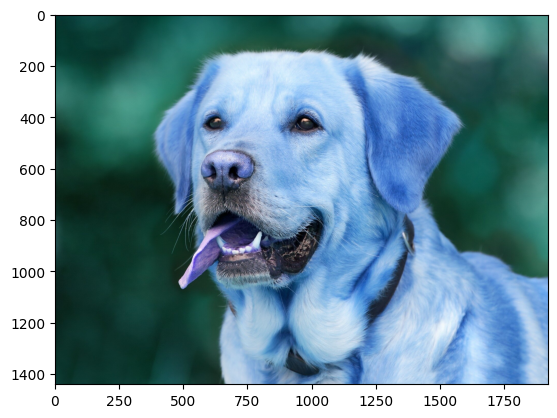

In [249]:
test_img3 = cv2.imread('/content/4-dog.jpg')
plt.imshow(test_img3)
test_img3 = test_img3/255
test_img3 = cv2.resize(test_img3, (256,256))
test_input3 = test_img3.reshape((1,256,256,3))

### **Making Predictions and Categorizing Output**

In [250]:
def predict(x):
  pred  = model_transfer.predict(x)
  if pred[0][0] < 0.5:
    print("cat")
  else:
    print("dog")

In [251]:
predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
cat


In [252]:
predict(test_input2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
dog


In [253]:
predict(test_input3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
dog


In [254]:
model_transfer.predict(test_input) # cat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


array([[0.04663645]], dtype=float32)

In [255]:
model_transfer.predict(test_input2)# predicted a dog correctly

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


array([[0.999874]], dtype=float32)

In [256]:
model_transfer.predict(test_input3) # dog

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


array([[1.]], dtype=float32)

trying our customized model

In [257]:
model2.predict(test_input) # cat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


array([[0.24072883]], dtype=float32)

In [258]:
model2.predict(test_input2)[0][0] # predicted wrongly the cat-like dog as cat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


np.float32(0.20423234)

In [259]:
model2.predict(test_input3)[0][0] # dog

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


np.float32(0.94293565)

### Model Performance Comparison: Transfer Learning vs. Custom CNN

* **Transfer Learning Model (`model_transfer`):**
  * Achieves high-confidence, decisive probabilities (e.g., `0.046` for a cat, and `0.999` to `1.0` for dogs).
  * Demonstrates exceptional separation and accuracy across distinct test cases.

* **Custom CNN (`model2`):**
  * Shows less confident or ambiguous outputs on edge cases (e.g., outputting `0.204` for a cat-like dog, leading to an incorrect classification).
  * While it handles clear cases well (like `0.942` for a dog), its decision boundaries are far more prone to confusion compared to the transfer learning architecture.

---

### Key Takeaway
The test results clearly validate why the transfer learning model is superior. By leveraging pre-trained features, it eliminates the boundary confusion seen in the custom scratch-built CNN, providing robust and reliable predictions on unseen images!

### **Model Deployment**

In [260]:
# Save the trained model
model_transfer.save('model_transfer.keras')